In [47]:
!pip install -q lightning pytorch-forecasting shap scikit-learn openpyxl

In [48]:
import os, gc, json, random, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import lightning.pytorch as pl
from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
from pytorch_forecasting.data import GroupNormalizer
from pytorch_forecasting.metrics import QuantileLoss
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import r2_score
import shap

from google.colab import drive
drive.mount("/content/drive", force_remount=True)

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
pl.seed_everything(SEED, workers=True)

BASE_DIR=Path("/content/drive/MyDrive")
SALES_FILE=BASE_DIR/"model_ready_category_dataset.csv"
OUTPUT_DIR=BASE_DIR/"model_6_2_trends_inner_validated_shap"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRENDS_IT_PATH=BASE_DIR
TRENDS_ES_PATH=BASE_DIR
ARCH_FILE=BASE_DIR/"model_6_1_tft_only_outputs"/"model_6_1_best_architecture.json"

DATE_COL="week_start"; CATEGORY_COL="Product Category"; TARGET_COL="weekly_quantity"
SEASONAL_PERIOD=52; MAX_HORIZON=12
FORECAST_HORIZONS=[4,8,12]
OUTER_ORIGINS={
    "spring_2025":"2025-04-07",
    "summer_2025":"2025-07-07",
    "early_autumn_2025":"2025-09-08",
    "q4_year_end_2025":"2025-10-06",
}
EPS=1e-12

TREND_YEAR_LAG=1

print("Sales:",SALES_FILE)
print("Model 6.1 architecture file:",ARCH_FILE)
print("Output:",OUTPUT_DIR)
if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()):
    raise FileExistsError(f"Output folder is not empty: {OUTPUT_DIR}")


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


Mounted at /content/drive
Sales: /content/drive/MyDrive/model_ready_category_dataset.csv
Model 6.1 architecture file: /content/drive/MyDrive/model_6_1_tft_only_outputs/model_6_1_best_architecture.json
Output: /content/drive/MyDrive/model_6_2_trends_inner_validated_shap


In [49]:
ITALY_TRENDS_FILES = {
    'borsa donna': 'borsa donna_google trends_Italy.csv',
    'portafoglio donna': 'portafoglio donna_google trends_Italy.csv',
    'portafoglio uomo': 'portafoglio uomo_google trends_Italy.csv',
    'guanti donna': 'guanti donna_google trends_Italy.csv',
    'guanti uomo': 'guanti uomo_google trends_Italy.csv',
    'sciarpa': 'sciarpa_google trends_Italy.csv',
    'sciarpa uomo': 'sciarpa uomo_google trends_Italy.csv',
    'stola': 'stola_google trends_Italy.csv',
    'cappello': 'cappello_google trends_Italy.csv',
    'berretto': 'berretto_google trends_Italy.csv',
    'berretto uomo': 'berretto uomo_google trends_Italy.csv',
    'borsa mare': 'borsa mare_google trends_Italy.csv',
    'borsa uomo': 'borsa uomo_google trends_Italy.csv',
    'telo mare': 'telo mare_google trends_Italy.csv',
    'scarpe donna': 'scarpe donna_google trends_Italy.csv',
    'pelliccia cappotto': 'pelliccia cappotto_google trends_Italy.csv',
    'cintura donna': 'cintura donna_google trends_Italy.csv',
    'cintura uomo': 'cintura uomo_google trends_Italy.csv',
    'vestito donna': 'vestito donna_google trends_Italy.csv',
    'vestito': 'vestito_google trends_Italy.csv',
    'tunica': 'tunica_google trends_Italy.csv',
    'gonna': 'gonna_google trends_Italy.csv',
    'camicia': 'camicia_google trends_Italy.csv',
    'camicetta': 'camicetta_google trends_Italy.csv',
    'pantaloni': 'pantaloni_google trends_Italy.csv',
    'pantaloncini': 'pantaloncini_google trends_Italy.csv',
    'pareo': 'pareo_google trends_Italy.csv',
    'cappa': 'cappa_google trends_Italy.csv',
    'caftano': 'caftano_google trends_Italy.csv',
    'portachiavi': 'portachiavi_google trends_Italy.csv',
    'zaino da viaggio': 'zaino da viaggio_google trends_Italy.csv',
    'pelletteria accessori': 'pelletteria accessori_google trends_Italy.csv',
}

SPAIN_TRENDS_FILES = {
    'bolso mujer': 'bolso mujer_google trends_Spain.csv',
    'bolso hombre': 'bolso hombre_google trends_Spain.csv',
    'cartera mujer': 'cartera mujer_google trends_Spain.csv',
    'cartera hombre': 'cartera hombre_google trends_Spain.csv',
    'guantes mujer': 'guantes mujer_google trends_Spain.csv',
    'guantes hombre': 'guantes hombre_google trends_Spain.csv',
    'ecarpe': 'echarpe_google trends_Spain.csv',
    'bufanda': 'bufanda_google trends_Spain.csv',
    'bufanda hombre': 'bufanda hombre_google trends_Spain.csv',
    'sombrero': 'sombrero_google trends_Spain.csv',
    'gorro': 'gorro_google trends_Spain.csv',
    'capa': 'capa_google trends_Spain.csv',
    'gorro hombre': 'gorro hombre_google trends_Spain.csv',
    'bolsa playa': 'bolsa playa_google trends_Spain.csv',
    'toalla playa': 'toalla playa_google trends_Spain.csv',
    'zapatos mujer': 'zapatos mujer_google trends_Spain.csv',
    'abrigo piel': 'abrigo piel_google trends_Spain.csv',
    'cinturon mujer': 'cinturon mujer_google trends_Spain.csv',
    'cinturon hombre': 'cinturon hombre_google trends_Spain.csv',
    'vestido': 'vestido_google trends_Spain.csv',
    'vestido mujer': 'vestido mujer_google trends_Spain.csv',
    'falda': 'falda_google trends_Spain.csv',
    'camisa': 'camisa_google trends_Spain.csv',
    'túnica': 'túnica_google trends_Spain.csv',
    'blusa': 'blusa_google trends_Spain.csv',
    'pantalones': 'pantalones_google trends_Spain.csv',
    'pantalones cortos': 'pantalones cortos_google trends_Spain.csv',
    'pareo': 'pareo_google trends_Spain.csv',
    'caftán': 'caftán_google trends_Spain.csv',
    'llavero': 'llavero_google trends_Spain.csv',
    'bolsa viaje mochila': 'bolsa viaje mochila_google trends_Spain.csv',
    'marroquineria': 'marroquineria_google trends_Spain.csv',
}

CATEGORY_TREND_MAP = {
    'ΤΣΑΝΤΑ ΓΥΝΑΙΚΕΙΑ': {'IT': [('borsa donna', 1.0)], 'ES': [('bolso mujer', 1.0)]},
    'ΑΝΔΡΙΚΗ ΤΣΑΝΤΑ': {'IT': [('borsa uomo', 1.0)], 'ES': [('bolso hombre', 1.0)]},
    'ΤΣΑΝΤΑ ΘΑΛΑΣΣΗΣ': {'IT': [('borsa mare', 1.0)], 'ES': [('bolsa playa', 1.0)]},
    'ΤΣΑΝΤΑ ΨΑΘΙΝΗ': {'IT': [('borsa mare', 0.60), ('borsa donna', 0.40)], 'ES': [('bolsa playa', 0.60), ('bolso mujer', 0.40)]},
    'ΤΑΞΙΔΙΟΥ': {'IT': [('zaino da viaggio', 1.0)], 'ES': [('bolsa viaje mochila', 1.0)]},
    'POUCH': {'IT': [('pelletteria accessori', 0.70), ('borsa donna', 0.30)], 'ES': [('marroquineria', 0.70), ('bolso mujer', 0.30)]},
    'ΠΟΡΤΟΦΟΛΙ ΓΥΝΑΙΚΕΙΟ': {'IT': [('portafoglio donna', 1.0)], 'ES': [('cartera mujer', 1.0)]},
    'ΠΟΡΤΟΦΟΛΙ ΑΝΔΡΙΚΟ': {'IT': [('portafoglio uomo', 1.0)], 'ES': [('cartera hombre', 1.0)]},
    'ΠΟΡΤΟΦΟΛΙ ΜΕΣΗΣ': {'IT': [('portafoglio donna', 0.50), ('portafoglio uomo', 0.50)], 'ES': [('cartera mujer', 0.50), ('cartera hombre', 0.50)]},
    'ΓΑΝΤΙ ΓΥΝΑΙΚΕΙΟ': {'IT': [('guanti donna', 1.0)], 'ES': [('guantes mujer', 1.0)]},
    'ΓΑΝΤΙ ΑΝΔΡΙΚΟ': {'IT': [('guanti uomo', 1.0)], 'ES': [('guantes hombre', 1.0)]},
    'ΚΑΣΚΟΛ': {'IT': [('sciarpa', 1.0)], 'ES': [('bufanda', 1.0)]},
    'ΚAΣΚΟΛ': {'IT': [('sciarpa', 1.0)], 'ES': [('bufanda', 1.0)]},
    'ΚΑΣΚΟΛ ΑΝΔΡΙΚΟ': {'IT': [('sciarpa uomo', 1.0)], 'ES': [('bufanda hombre', 1.0)]},
    'ΕΣΑΡΠΑ': {'IT': [('stola', 1.0)], 'ES': [('ecarpe', 1.0)]},
    'ΛΑΙΜΟΣ': {'IT': [('sciarpa', 0.50), ('stola', 0.50)], 'ES': [('bufanda', 0.50), ('ecarpe', 0.50)]},
    'ΚΑΠΕΛΟ': {'IT': [('cappello', 1.0)], 'ES': [('sombrero', 1.0)]},
    'ΚAΠΕΛΟ': {'IT': [('cappello', 1.0)], 'ES': [('sombrero', 1.0)]},
    'ΣΚΟΥΦΟΣ': {'IT': [('berretto', 1.0)], 'ES': [('gorro', 1.0)]},
    'ΣΚΟΥΦΟΣ ΑΝΔΡΙΚΟΣ': {'IT': [('berretto uomo', 1.0)], 'ES': [('gorro hombre', 1.0)]},
    'ΠΑΠΟΥΤΣΙΑ': {'IT': [('scarpe donna', 1.0)], 'ES': [('zapatos mujer', 1.0)]},
    'ΓΟΥΝΑ': {'IT': [('pelliccia cappotto', 1.0)], 'ES': [('abrigo piel', 1.0)]},
    'ΚΑΠΑ': {'IT': [('cappa', 1.0)], 'ES': [('capa', 1.0)]},
    'ΖΩΝΗ ΓΥΝΑΙΚΕΙΑ': {'IT': [('cintura donna', 1.0)], 'ES': [('cinturon mujer', 1.0)]},
    'ΖΩΝΗ ΑΝΔΡΙΚΗ': {'IT': [('cintura uomo', 1.0)], 'ES': [('cinturon hombre', 1.0)]},
    'ΙΜΑΝΤΑΣ': {'IT': [('cintura donna', 0.50), ('cintura uomo', 0.50)], 'ES': [('cinturon mujer', 0.50), ('cinturon hombre', 0.50)]},
    'ΦΟΡΕΜΑ': {'IT': [('vestito donna', 0.60), ('vestito', 0.40)], 'ES': [('vestido mujer', 0.60), ('vestido', 0.40)]},
    'ΦΟΥΣΤΑ': {'IT': [('gonna', 1.0)], 'ES': [('falda', 1.0)]},
    'ΠΟΥΚΑΜΙΣΑ': {'IT': [('camicia', 1.0)], 'ES': [('camisa', 1.0)]},
    'ΤΟΥΝΙΚ': {'IT': [('tunica', 1.0)], 'ES': [('túnica', 1.0)]},
    'ΑΜΠΙΓΙΕ': {'IT': [('vestito donna', 0.70), ('scarpe donna', 0.30)], 'ES': [('vestido mujer', 0.70), ('zapatos mujer', 0.30)]},
    'ΚΡΟΠ ΤΟΠ': {'IT': [('camicetta', 1.0)], 'ES': [('blusa', 1.0)]},
    'ΜΠΛΟΥΖΑ': {'IT': [('camicetta', 1.0)], 'ES': [('blusa', 1.0)]},
    'ΠΑΝΤΕΛΟΝΙ': {'IT': [('pantaloni', 1.0)], 'ES': [('pantalones', 1.0)]},
    'ΣΟΡΤΣ': {'IT': [('pantaloncini', 0.90), ('pantaloni', 0.10)], 'ES': [('pantalones cortos', 0.90), ('pantalones', 0.10)]},
    'ΠΑΡΕΟ': {'IT': [('pareo', 1.0)], 'ES': [('pareo', 1.0)]},
    'ΠΕΤΣΕΤΑ ΘΑΛΑΣΣΗΣ': {'IT': [('telo mare', 1.0)], 'ES': [('toalla playa', 1.0)]},
    'ΚΑΦΤΑΝΙ': {'IT': [('caftano', 1.0)], 'ES': [('caftán', 1.0)]},
    'ΜΠΡΕΛΟΚ': {'IT': [('portachiavi', 1.0)], 'ES': [('llavero', 1.0)]},
    'ΣΑΚΟΥΛΑ': {'IT': [('pelletteria accessori', 1.0)], 'ES': [('marroquineria', 1.0)]},
    'ΚΡΕΜΑΣΤΡΑ': {'IT': [('pelletteria accessori', 1.0)], 'ES': [('marroquineria', 1.0)]},
    'ΥΛΙΚΟ ΠΡΟΒΟΛΗΣ': {'IT': [('pelletteria accessori', 1.0)], 'ES': [('marroquineria', 1.0)]},
}

DEFAULT_TREND_MAP = {
    'IT': [('pelletteria accessori', 0.50), ('borsa donna', 0.50)],
    'ES': [('marroquineria', 0.50), ('bolso mujer', 0.50)],
}


def load_trends_data(files_dict, base_path, country_code):
    """Load monthly raw/historical Google Trends values (0-100 -> 0-1)."""
    dfs = []
    missing = []
    for keyword, filename in files_dict.items():
        filepath = Path(base_path) / filename
        if not filepath.exists():
            missing.append(str(filepath))
            continue
        tmp = pd.read_csv(filepath)
        if tmp.shape[1] < 2:
            raise ValueError(f"Trend file must have at least two columns: {filepath}")
        tmp = tmp.iloc[:, :2].copy()
        tmp.columns = ["Time", keyword]
        tmp["Time"] = pd.to_datetime(tmp["Time"], errors="coerce")
        tmp[keyword] = pd.to_numeric(tmp[keyword], errors="coerce") / 100.0
        tmp = tmp.dropna(subset=["Time", keyword])
        tmp["Year"] = tmp["Time"].dt.year.astype(int)
        tmp["Month"] = tmp["Time"].dt.month.astype(int)
        if tmp.duplicated(["Year","Month"]).any():
            raise ValueError(f"Duplicate month in {filepath}")
        dfs.append(tmp[["Year","Month",keyword]])

    if missing:
        raise FileNotFoundError(
            "Missing Google Trends files. No zero-imputation is allowed for the ablation.\n" + "\n".join(missing)
        )
    if not dfs:
        raise ValueError(f"No Google Trends files loaded for {country_code}")

    trends_df = dfs[0]
    for d in dfs[1:]:
        trends_df = trends_df.merge(d, on=["Year","Month"], how="outer", validate="one_to_one")
    trends_df = trends_df.sort_values(["Year","Month"]).reset_index(drop=True)
    print(f"{country_code} trends loaded:", trends_df.shape,
          "range:", f"{trends_df.Year.min()}-{trends_df.Month.min():02d}", "to",
          f"{trends_df.Year.max()}-{trends_df.Month.max():02d}")
    return trends_df

trends_it = load_trends_data(ITALY_TRENDS_FILES, TRENDS_IT_PATH, "IT")
trends_es = load_trends_data(SPAIN_TRENDS_FILES, TRENDS_ES_PATH, "ES")

def compute_weighted_trend(source_year, month, category, country):
    mapping = CATEGORY_TREND_MAP.get(category, DEFAULT_TREND_MAP)
    if country == "IT":
        pairs, df_t = mapping.get("IT", DEFAULT_TREND_MAP["IT"]), trends_it
    elif country == "ES":
        pairs, df_t = mapping.get("ES", DEFAULT_TREND_MAP["ES"]), trends_es
    else:
        raise ValueError(country)

    row = df_t[(df_t["Year"] == int(source_year)) & (df_t["Month"] == int(month))]
    if len(row) != 1:
        return np.nan
    vals=[]
    for kw,w in pairs:
        if kw not in row.columns or pd.isna(row[kw].iloc[0]):
            return np.nan
        vals.append(w * float(row[kw].iloc[0]))
    return float(np.sum(vals))

expected_files = list(ITALY_TRENDS_FILES.values()) + list(SPAIN_TRENDS_FILES.values())
print("Expected trend files:", len(expected_files))
print("All expected trend files loaded successfully.")

IT trends loaded: (61, 34) range: 2020-01 to 2025-12
ES trends loaded: (61, 34) range: 2020-01 to 2025-12
Expected trend files: 64
All expected trend files loaded successfully.


In [50]:
if not SALES_FILE.exists():
    raise FileNotFoundError(SALES_FILE)
raw=pd.read_csv(SALES_FILE); raw.columns=[c.strip() for c in raw.columns]
required=[CATEGORY_COL,DATE_COL,TARGET_COL]
missing=[c for c in required if c not in raw.columns]
if missing: raise ValueError(f"Missing required columns: {missing}")
raw=raw[required].copy()
raw[DATE_COL]=pd.to_datetime(raw[DATE_COL],errors="coerce")
raw[TARGET_COL]=pd.to_numeric(raw[TARGET_COL],errors="coerce")
raw=raw.dropna(subset=required)
raw[CATEGORY_COL]=raw[CATEGORY_COL].astype(str).str.strip()
raw[TARGET_COL]=raw[TARGET_COL].clip(lower=0)
if raw.duplicated([CATEGORY_COL,DATE_COL]).any(): raise ValueError("Duplicate category-week observations detected.")

categories=sorted(raw[CATEGORY_COL].unique())
dataset_min,dataset_max=raw[DATE_COL].min(),raw[DATE_COL].max()
all_weeks=pd.date_range(dataset_min,dataset_max,freq="W-MON")
panel_index=pd.MultiIndex.from_product([categories,all_weeks],names=[CATEGORY_COL,DATE_COL])
weekly=raw.set_index([CATEGORY_COL,DATE_COL]).reindex(panel_index).reset_index()
weekly[TARGET_COL]=weekly[TARGET_COL].fillna(0.0).clip(lower=0)
weekly=weekly.rename(columns={DATE_COL:"week",TARGET_COL:"target"})
weekly["series_id"]=weekly[CATEGORY_COL].astype(str)
weekly=weekly.sort_values(["series_id","week"]).reset_index(drop=True)

week_to_idx={w:i for i,w in enumerate(sorted(weekly["week"].unique()))}
weekly["time_idx"]=weekly["week"].map(week_to_idx).astype(int)
weekly["month"]=weekly["week"].dt.month.astype(float)
weekly["quarter"]=weekly["week"].dt.quarter.astype(float)
weekly["week_of_year"]=weekly["week"].dt.isocalendar().week.astype(float)
weekly["week_sin"]=np.sin(2*np.pi*weekly["week_of_year"]/52.0)
weekly["week_cos"]=np.cos(2*np.pi*weekly["week_of_year"]/52.0)
weekly["month_sin"]=np.sin(2*np.pi*weekly["month"]/12.0)
weekly["month_cos"]=np.cos(2*np.pi*weekly["month"]/12.0)

weekly["seasonal_lag_52"]=weekly.groupby("series_id")["target"].shift(52)
weekly["seasonal_lag_52_available"]=weekly["seasonal_lag_52"].notna().astype(float)
weekly["seasonal_lag_52"]=weekly["seasonal_lag_52"].fillna(0.0)

weekly["trend_source_year"]=(weekly["week"].dt.year-TREND_YEAR_LAG).astype(int)
weekly["trend_source_month"]=weekly["week"].dt.month.astype(int)
weekly["trend_source_date"]=pd.to_datetime(dict(
    year=weekly["trend_source_year"], month=weekly["trend_source_month"], day=1
))

def combined_lagged_trend(source_year,month,category):
    it=compute_weighted_trend(source_year,month,category,"IT")
    es=compute_weighted_trend(source_year,month,category,"ES")
    if not (np.isfinite(it) and np.isfinite(es)):
        return np.nan
    return float((it+es)/2.0)

weekly["google_trends_lagged_1y"]=weekly.apply(
    lambda r: combined_lagged_trend(r["trend_source_year"],r["trend_source_month"],r[CATEGORY_COL]), axis=1
)

trend_missing=weekly["google_trends_lagged_1y"].isna()
if trend_missing.any():
    ex=weekly.loc[trend_missing,[CATEGORY_COL,"week","trend_source_year","trend_source_month"]].head(20)
    raise ValueError(f"Missing lagged Google Trends values for {trend_missing.sum()} category-weeks. Examples:\n{ex}")

print("Shape:",weekly.shape)
print("Categories:",weekly.series_id.nunique())
print("Date range:",weekly.week.min().date(),"to",weekly.week.max().date())
print("Trend source range:",weekly.trend_source_date.min().date(),"to",weekly.trend_source_date.max().date())
print("Lagged Trends feature range:",weekly.google_trends_lagged_1y.min(),weekly.google_trends_lagged_1y.max())
display(weekly.head())
weekly.to_csv(OUTPUT_DIR/"model_6_2_dataset.csv",index=False,encoding="utf-8-sig")
base_file=BASE_DIR/'model_6_1_tft_only_outputs'/'model_6_1_dataset.csv'
if not base_file.exists():raise FileNotFoundError(base_file)
base=pd.read_csv(base_file,encoding='utf-8-sig')
cols=['series_id','week','target','time_idx','month','quarter','week_of_year','week_sin','week_cos','month_sin','month_cos','seasonal_lag_52','seasonal_lag_52_available']
a=weekly[cols].sort_values(['series_id','week']).reset_index(drop=True)
b=base[cols].sort_values(['series_id','week']).reset_index(drop=True)
assert a.shape==b.shape
for col in cols:
    if col in ('series_id','week'):
        assert a[col].astype(str).equals(b[col].astype(str)),f'Baseline mismatch: {col}'
    else:
        assert np.allclose(a[col].astype(float),b[col].astype(float),rtol=1e-9,atol=1e-9,equal_nan=True),f'Baseline mismatch: {col}'
print('PASS: M6.1 exact base panel and sales features')

Shape: (6200, 18)
Categories: 40
Date range: 2023-01-09 to 2025-12-22
Trend source range: 2022-01-01 to 2024-12-01
Lagged Trends feature range: 0.01 1.0


,Product Category,week,target,series_id,time_idx,month,quarter,week_of_year,week_sin,week_cos,month_sin,month_cos,seasonal_lag_52,seasonal_lag_52_available,trend_source_year,trend_source_month,trend_source_date,google_trends_lagged_1y
0,AΜΠΙΓΙΕ,2023-01-09,9.0,AΜΠΙΓΙΕ,0,1.0,1.0,2.0,0.239316,0.970942,0.500000,0.866025,0.0,0.0,2022,1,2022-01-01,0.455
1,AΜΠΙΓΙΕ,2023-01-16,5.0,AΜΠΙΓΙΕ,1,1.0,1.0,3.0,0.354605,0.935016,0.500000,0.866025,0.0,0.0,2022,1,2022-01-01,0.455
2,AΜΠΙΓΙΕ,2023-01-23,153.0,AΜΠΙΓΙΕ,2,1.0,1.0,4.0,0.464723,0.885456,0.500000,0.866025,0.0,0.0,2022,1,2022-01-01,0.455
3,AΜΠΙΓΙΕ,2023-01-30,87.0,AΜΠΙΓΙΕ,3,1.0,1.0,5.0,0.568065,0.822984,0.500000,0.866025,0.0,0.0,2022,1,2022-01-01,0.455
4,AΜΠΙΓΙΕ,2023-02-06,139.0,AΜΠΙΓΙΕ,4,2.0,1.0,6.0,0.663123,0.748511,0.866025,0.500000,0.0,0.0,2022,2,2022-02-01,0.560


PASS: M6.1 exact base panel and sales features


In [51]:
from collections import defaultdict

WEEKLY_FEATURES = ['gt_weekly_lag52', 'gt_weekly_lag52_available']
weekly_source_audit=[]
weekly_calibration_audit=[]


def load_weekly_historical(country, keyword, monthly_filename):
    root=Path(TRENDS_IT_PATH if country=='IT' else TRENDS_ES_PATH)
    base=monthly_filename[:-4]+'_weekly'
    candidates=[root/(base+'.csv'),root/(base+'(1).csv')]
    present=[p for p in candidates if p.exists()]
    if len(present)!=1:
        raise FileNotFoundError(f'Expected one weekly file for {country}/{keyword}: {present}')
    z=pd.read_csv(present[0],sep=';',encoding='utf-8-sig')
    if not {'week_start','trends_value','source_period'}.issubset(z):
        raise ValueError(f'Unexpected weekly format: {present[0]}')
    z['week_start']=pd.to_datetime(z.week_start,dayfirst=True,errors='raise')
    z['trends_value']=pd.to_numeric(z.trends_value,errors='raise')
    z['source_period']=pd.to_numeric(z.source_period,errors='raise').astype(int)
    z=z.loc[z.source_period.between(2022,2024)].copy()
    if z.duplicated(['week_start','source_period']).any():
        raise ValueError(f'Duplicate weekly row: {present[0]}')

    z['week_end']=z.week_start+pd.Timedelta(days=6)
    ref=pd.read_csv(root/monthly_filename,encoding='utf-8-sig')
    ref=ref.iloc[:,:2].copy();ref.columns=['month','monthly_value']
    ref['month']=pd.to_datetime(ref.month,errors='raise').dt.to_period('M').dt.to_timestamp()
    ref['monthly_value']=pd.to_numeric(ref.monthly_value,errors='raise')/100.

    rows=[]
    for r in z.itertuples(index=False):
        for d in pd.date_range(r.week_start,periods=7,freq='D'):
            rows.append((r.source_period,d.to_period('M').to_timestamp(),float(r.trends_value)/100.))
    daily=pd.DataFrame(rows,columns=['source_period','month','v'])
    grouped=daily.groupby(['source_period','month'],as_index=False).agg(x=('v','mean'),days=('v','size'))
    grouped=grouped.merge(ref,on='month',how='inner',validate='many_to_one')
    grouped=grouped.loc[grouped.days>=grouped.month.dt.days_in_month-3]
    scales={}
    for yr,g in grouped.groupby('source_period'):
        x=g.x.to_numpy(float); y=g.monthly_value.to_numpy(float)
        valid=np.isfinite(x)&np.isfinite(y)&(x>1e-8)
        if valid.sum()>=2:
            scales[int(yr)]=float(np.dot(x[valid],y[valid])/np.dot(x[valid],x[valid]))
        weekly_calibration_audit.append({'country':country,'keyword':keyword,'source_period':int(yr),'months':int(valid.sum()),'calibrated':int(yr) in scales,'calibration_rmse':float(np.sqrt(np.mean((scales[int(yr)]*x[valid]-y[valid])**2))) if int(yr) in scales else np.nan})
    z['scale']=z.source_period.map(scales)
    z['value']=z.trends_value/100.*z.scale
    z=z.loc[z.value.notna()].copy()

    z['sales_week']=z.week_end+pd.to_timedelta((7-z.week_end.dt.weekday)%7,unit='D')
    z=z.sort_values(['sales_week','source_period']).drop_duplicates('sales_week',keep='last')
    return z.set_index('sales_week').value.sort_index()

weekly_series={}
for country, mapping in [('IT',ITALY_TRENDS_FILES),('ES',SPAIN_TRENDS_FILES)]:
    for kw,filename in mapping.items():
        weekly_series[(country,kw)]=load_weekly_historical(country,kw,filename)


def category_weekly_signal(category, source_week):
    mapping=CATEGORY_TREND_MAP.get(category,DEFAULT_TREND_MAP)
    values=[]
    for country in ['IT','ES']:
        weighted=[]
        for kw,weight in mapping.get(country,DEFAULT_TREND_MAP[country]):
            val=weekly_series[(country,kw)].get(source_week,np.nan)
            if not np.isfinite(val):return np.nan
            weighted.append(float(weight)*float(val))
        values.append(sum(weighted))
    return float(np.mean(values))


weekly['gt_weekly_source_week']=weekly.week-pd.Timedelta(weeks=52)
weekly['gt_weekly_lag52']=weekly.apply(lambda r: category_weekly_signal(r.series_id,r.gt_weekly_source_week),axis=1)
weekly['gt_weekly_lag52_available']=weekly.gt_weekly_lag52.notna().astype(float)

weekly['gt_monthly_reference_for_weekly_source']=weekly.apply(
    lambda r: combined_lagged_trend(r.gt_weekly_source_week.year,
                                    r.gt_weekly_source_week.month,r.series_id),axis=1)
weekly['gt_weekly_residual_lag52']=(weekly['gt_weekly_lag52']-
    weekly['gt_monthly_reference_for_weekly_source'])
weekly.loc[weekly.gt_weekly_lag52_available.eq(0),'gt_weekly_residual_lag52']=0.0
weekly['gt_weekly_residual_lag52']=weekly.gt_weekly_residual_lag52.fillna(0.0)
assert np.isfinite(weekly['gt_weekly_residual_lag52']).all()
weekly['gt_weekly_lag52']=weekly.gt_weekly_lag52.fillna(0.0)
assert np.isfinite(weekly[WEEKLY_FEATURES].to_numpy(float)).all()
for label,date in OUTER_ORIGINS.items():
    origin=pd.Timestamp(date)
    decoder=weekly.loc[weekly.week.between(origin,origin+pd.Timedelta(weeks=MAX_HORIZON-1))]
    assert (decoder.gt_weekly_source_week+pd.Timedelta(days=0)<origin).all()
    weekly_source_audit.append({'origin':label,'decoder_coverage':float(decoder.gt_weekly_lag52_available.mean()),'train_coverage':float(weekly.loc[weekly.week<origin,'gt_weekly_lag52_available'].mean())})
weekly.to_csv(OUTPUT_DIR/'model_6_2_dataset.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(weekly_calibration_audit).to_csv(OUTPUT_DIR/'weekly_calibration_audit.csv',index=False)
pd.DataFrame(weekly_source_audit).to_csv(OUTPUT_DIR/'weekly_feature_coverage.csv',index=False)
print('Weekly seasonal feature coverage by origin:')
display(pd.DataFrame(weekly_source_audit))


Weekly seasonal feature coverage by origin:


,origin,decoder_coverage,train_coverage
0,spring_2025,1.0,1.0
1,summer_2025,1.0,1.0
2,early_autumn_2025,1.0,1.0
3,q4_year_end_2025,1.0,1.0


In [52]:
scenario_rows=[]
for label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s)
    for h in FORECAST_HORIZONS:
        dates=pd.date_range(origin,periods=h,freq="W-MON")
        if dates[-1]>dataset_max: raise ValueError(f"{label}, h={h} exceeds dataset end")
        scenario_rows.append({"scenario_id":f"{label}_h{h}","outer_origin_label":label,"outer_origin":origin,
                              "horizon_weeks":h,"test_start":dates[0],"test_end":dates[-1]})
scenarios=pd.DataFrame(scenario_rows); display(scenarios)
scenarios.to_csv(OUTPUT_DIR/"model_6_2_common_rolling_origin_scenarios.csv",index=False)

def mae(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float); return float(np.mean(np.abs(a-p)))
def rmse(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float); return float(np.sqrt(np.mean((a-p)**2)))
def mape(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float); mask=np.abs(a)>EPS
    return np.nan if mask.sum()==0 else float(np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100)
def smape(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float); d=np.abs(a)+np.abs(p)
    return float(np.mean(np.where(d>EPS,2*np.abs(a-p)/d,0))*100)
def mase_scale_info(y_train,m=52):
    y=np.asarray(y_train,float)
    if len(y)<=m:return np.nan,"insufficient_history"
    scale=float(np.mean(np.abs(y[m:]-y[:-m])))
    if not np.isfinite(scale):return np.nan,"non_finite_scale"
    if scale<=EPS:return np.nan,"zero_seasonal_scale"
    return scale,"valid"
def evaluate(a,p,y_train,m=52):
    scale,status=mase_scale_info(y_train,m)
    return {"MAE":mae(a,p),"RMSE":rmse(a,p),"MAPE":mape(a,p),
            "MAPE_N":int(np.sum(np.abs(np.asarray(a,float))>EPS)),"sMAPE":smape(a,p),
            "MASE":np.nan if not np.isfinite(scale) else mae(a,p)/scale,
            "MASE_scale":scale,"MASE_status":status}
print("MASE seasonal period:",SEASONAL_PERIOD)

,scenario_id,outer_origin_label,outer_origin,horizon_weeks,test_start,test_end
0,spring_2025_h4,spring_2025,2025-04-07,4,2025-04-07,2025-04-28
1,spring_2025_h8,spring_2025,2025-04-07,8,2025-04-07,2025-05-26
2,spring_2025_h12,spring_2025,2025-04-07,12,2025-04-07,2025-06-23
3,summer_2025_h4,summer_2025,2025-07-07,4,2025-07-07,2025-07-28
4,summer_2025_h8,summer_2025,2025-07-07,8,2025-07-07,2025-08-25
5,summer_2025_h12,summer_2025,2025-07-07,12,2025-07-07,2025-09-22
6,early_autumn_2025_h4,early_autumn_2025,2025-09-08,4,2025-09-08,2025-09-29
7,early_autumn_2025_h8,early_autumn_2025,2025-09-08,8,2025-09-08,2025-10-27
8,early_autumn_2025_h12,early_autumn_2025,2025-09-08,12,2025-09-08,2025-11-24
9,q4_year_end_2025_h4,q4_year_end_2025,2025-10-06,4,2025-10-06,2025-10-27


MASE seasonal period: 52


In [53]:
LOCKED_6_1={
    "encoder_length":39,
    "feature_set":"cyclical",
    "hidden_size":8,
    "attention_head_size":4,
    "dropout":0.15,
    "hidden_continuous_size":4,
    "learning_rate":0.0035640595324118764,
    "gradient_clip_val":0.5,
    "final_epochs":10,
    "best_trial":2,
    "best_cv_multi_horizon_mase":3.1738197367141248,
}

if ARCH_FILE.exists():
    loaded=json.load(open(ARCH_FILE))
    for k in ["encoder_length","hidden_size","attention_head_size","dropout","hidden_continuous_size","learning_rate","gradient_clip_val","final_epochs"]:
        if not np.isclose(float(loaded[k]),float(LOCKED_6_1[k])):
            raise ValueError(f"Model 6.1 architecture mismatch for {k}: file={loaded[k]} locked={LOCKED_6_1[k]}")
    if str(loaded.get("feature_set"))!=LOCKED_6_1["feature_set"]:
        raise ValueError("Model 6.1 feature_set mismatch")
    print("Loaded and verified Model 6.1 architecture JSON.")
else:
    print("Architecture JSON not found; using locked values copied from the completed Model 6.1 run.")

best_params={k:LOCKED_6_1[k] for k in ["encoder_length","feature_set","hidden_size","attention_head_size","dropout","hidden_continuous_size","learning_rate","gradient_clip_val"]}
BEST_EPOCHS=int(LOCKED_6_1["final_epochs"])

CALENDAR_FEATURE_SETS={
    "cyclical":["time_idx","week_sin","week_cos","month_sin","month_cos"],
    "full":["time_idx","month","quarter","week_of_year","week_sin","week_cos","month_sin","month_cos"],
}
STATIC_CATEGORICALS=["series_id"]
UNKNOWN_REALS=["target"]
BASE_KNOWN_REALS=CALENDAR_FEATURE_SETS[best_params["feature_set"]]+["seasonal_lag_52","seasonal_lag_52_available"]

CANDIDATE_TRENDS={
    'monthly_only':['google_trends_lagged_1y'],
    'monthly_weekly':['google_trends_lagged_1y','gt_weekly_lag52','gt_weekly_lag52_available'],
    'monthly_residual':['google_trends_lagged_1y','gt_weekly_residual_lag52','gt_weekly_lag52_available'],
}
KNOWN_REALS=BASE_KNOWN_REALS+CANDIDATE_TRENDS['monthly_weekly']

print("Locked Model 6.1 configuration:",LOCKED_6_1)
print("Incremental M6.2 features: monthly lag + calibrated weekly lag52")
print("Known reals:",KNOWN_REALS)

def make_training_dataset(train_df,prediction_length):
    enc=best_params["encoder_length"]
    return TimeSeriesDataSet(train_df.copy(),time_idx="time_idx",target="target",group_ids=["series_id"],
        min_encoder_length=max(26,min(enc,39)),max_encoder_length=enc,
        min_prediction_length=prediction_length,max_prediction_length=prediction_length,
        static_categoricals=STATIC_CATEGORICALS,time_varying_known_reals=KNOWN_REALS,
        time_varying_unknown_reals=UNKNOWN_REALS,
        target_normalizer=GroupNormalizer(groups=["series_id"],transformation="softplus"),
        add_relative_time_idx=True,add_target_scales=True,add_encoder_length=True,allow_missing_timesteps=False)

def prediction_frame(origin,horizon=12):
    origin=pd.Timestamp(origin); enc_len=best_params["encoder_length"]
    enc=weekly[weekly.week<origin].groupby("series_id",group_keys=False).tail(enc_len).copy()
    future=weekly[(weekly.week>=origin)&(weekly.week<origin+pd.Timedelta(weeks=horizon))].copy()
    if future.groupby("series_id").size().min()!=horizon: raise ValueError("Incomplete future calendar frame")
    future["target"]=0.0
    return pd.concat([enc,future],ignore_index=True).sort_values(["series_id","time_idx"])

def extract_predictions(model,loader):
    out=model.predict(loader,mode="prediction",return_index=True)
    if hasattr(out,"output"): pred,idx=out.output,out.index.copy()
    else: pred,idx=out[0],out[1].copy()
    pred=pred.detach().cpu().numpy() if torch.is_tensor(pred) else np.asarray(pred)
    return pred,idx

Loaded and verified Model 6.1 architecture JSON.
Locked Model 6.1 configuration: {'encoder_length': 39, 'feature_set': 'cyclical', 'hidden_size': 8, 'attention_head_size': 4, 'dropout': 0.15, 'hidden_continuous_size': 4, 'learning_rate': 0.0035640595324118764, 'gradient_clip_val': 0.5, 'final_epochs': 10, 'best_trial': 2, 'best_cv_multi_horizon_mase': 3.1738197367141248}
Incremental M6.2 features: monthly lag + calibrated weekly lag52
Known reals: ['time_idx', 'week_sin', 'week_cos', 'month_sin', 'month_cos', 'seasonal_lag_52', 'seasonal_lag_52_available', 'google_trends_lagged_1y', 'gt_weekly_lag52', 'gt_weekly_lag52_available']


In [54]:
def fit_final_tft(train_df):
    pl.seed_everything(SEED,workers=True)
    training=make_training_dataset(train_df,MAX_HORIZON)
    loader=training.to_dataloader(train=True,batch_size=64,num_workers=0)
    trainer=pl.Trainer(max_epochs=BEST_EPOCHS,min_epochs=BEST_EPOCHS,accelerator="auto",devices=1,
        gradient_clip_val=best_params["gradient_clip_val"],logger=False,enable_checkpointing=False,
        enable_model_summary=False,enable_progress_bar=False)
    model=TemporalFusionTransformer.from_dataset(training,learning_rate=best_params["learning_rate"],
        hidden_size=best_params["hidden_size"],attention_head_size=best_params["attention_head_size"],
        dropout=best_params["dropout"],hidden_continuous_size=best_params["hidden_continuous_size"],
        output_size=7,loss=QuantileLoss(),reduce_on_plateau_patience=4)
    trainer.fit(model,loader)
    return model,training

INNER_ORIGINS=['2024-04-01','2024-07-01','2024-10-07']
inner_rows=[]
for candidate_name, trend_features in CANDIDATE_TRENDS.items():
    KNOWN_REALS=BASE_KNOWN_REALS+trend_features
    for origin_s in INNER_ORIGINS:
        origin=pd.Timestamp(origin_s)
        assert origin+pd.Timedelta(weeks=MAX_HORIZON-1)<pd.Timestamp('2025-01-01')
        train_df=weekly.loc[weekly.week<origin].copy()

        model, training=fit_final_tft(train_df)
        pred_frame=prediction_frame(origin,MAX_HORIZON)
        pred_ds=TimeSeriesDataSet.from_dataset(training,pred_frame,predict=True,stop_randomization=True)
        pred_loader=pred_ds.to_dataloader(train=False,batch_size=64,num_workers=0)
        preds, pred_index=extract_predictions(model,pred_loader)
        for i,row in pred_index.reset_index(drop=True).iterrows():
            cat=str(row['series_id'])
            actual=weekly.loc[(weekly.series_id==cat)&(weekly.week>=origin)&
                              (weekly.week<origin+pd.Timedelta(weeks=MAX_HORIZON)),'target'].to_numpy(float)
            hist=train_df.loc[train_df.series_id==cat].sort_values('week').target.to_numpy(float)
            pred=np.maximum(np.asarray(preds[i],float).reshape(-1)[:MAX_HORIZON],0.0)
            assert len(actual)==MAX_HORIZON and len(pred)==MAX_HORIZON
            for h in FORECAST_HORIZONS:
                m=evaluate(actual[:h],pred[:h],hist,SEASONAL_PERIOD)
                inner_rows.append({'candidate':candidate_name,'origin':origin_s,'category':cat,
                                   'horizon':h,'MASE':m['MASE']})
        del model,training,pred_ds,pred_loader;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
inner_df=pd.DataFrame(inner_rows)
inner_df.to_csv(OUTPUT_DIR/'inner_validation_all_candidates.csv',index=False)

inner_cat=inner_df.groupby(['candidate','category'],as_index=False).MASE.mean()
inner_summary=inner_cat.groupby('candidate',as_index=False).MASE.mean().sort_values(['MASE','candidate'])
inner_summary.to_csv(OUTPUT_DIR/'inner_validation_candidate_summary.csv',index=False)
display(inner_summary)
SELECTED_CANDIDATE=str(inner_summary.iloc[0]['candidate'])
KNOWN_REALS=BASE_KNOWN_REALS+CANDIDATE_TRENDS[SELECTED_CANDIDATE]
print('SELECTED from pre-2025 validation:',SELECTED_CANDIDATE,'features:',KNOWN_REALS)
(OUTPUT_DIR/'selected_trends_features.json').write_text(json.dumps({
    'selected_candidate':SELECTED_CANDIDATE,'trend_features':CANDIDATE_TRENDS[SELECTED_CANDIDATE],
    'inner_origins':INNER_ORIGINS,'outer_tests_used_for_selection':False},indent=2))

outer_results=[]; outer_forecasts=[]; outer_model_meta=[]
models_by_origin={}; training_by_origin={}
for origin_label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s); print("\n"+"="*90); print("OUTER TEST:",origin_label,origin.date())
    train_df=weekly[weekly.week<origin].copy(); assert train_df.week.max()<origin
    model,training=fit_final_tft(train_df)
    pred_frame=prediction_frame(origin,MAX_HORIZON)
    pred_ds=TimeSeriesDataSet.from_dataset(training,pred_frame,predict=True,stop_randomization=True)
    pred_loader=pred_ds.to_dataloader(train=False,batch_size=64,num_workers=0)
    pred_array,pred_index=extract_predictions(model,pred_loader)
    if "series_id" not in pred_index.columns: raise ValueError("Prediction index lacks series_id")
    for i,row in pred_index.reset_index(drop=True).iterrows():
        cat=str(row["series_id"])
        if cat not in categories: continue
        p=np.maximum(np.asarray(pred_array[i],float).reshape(-1)[:MAX_HORIZON],0.0)
        actual_df=weekly[(weekly.series_id==cat)&(weekly.week>=origin)].sort_values("week").head(MAX_HORIZON)
        if len(actual_df)!=MAX_HORIZON or len(p)!=MAX_HORIZON: raise ValueError(f"Incomplete forecast: {cat}, {origin_label}")
        a=actual_df.target.to_numpy(float)
        hist=train_df[train_df.series_id==cat].sort_values("week").target.to_numpy(float)
        for step,(d,yy,pp) in enumerate(zip(actual_df.week,a,p),1):
            rr=actual_df.iloc[step-1]
            outer_forecasts.append({"outer_origin_label":origin_label,"outer_origin":origin,"category":cat,
                "week":d,"forecast_step":step,"y_true":yy,"y_pred":pp,"absolute_error":abs(yy-pp),
                "seasonal_lag_52":float(rr.seasonal_lag_52),
                "google_trends_lagged_1y":float(rr.google_trends_lagged_1y),
                "gt_weekly_lag52":float(rr.gt_weekly_lag52),
                                    "gt_weekly_residual_lag52":float(rr.gt_weekly_residual_lag52),
                "gt_weekly_lag52_available":float(rr.gt_weekly_lag52_available),
                "trend_source_date":rr.trend_source_date})
        for h in FORECAST_HORIZONS:
            met=evaluate(a[:h],p[:h],hist,SEASONAL_PERIOD)
            outer_results.append({"scenario_id":f"{origin_label}_h{h}","outer_origin_label":origin_label,
                                  "outer_origin":origin,"horizon_weeks":h,"category":cat,**met})
    outer_model_meta.append({"outer_origin_label":origin_label,"outer_origin":origin,"training_end":train_df.week.max(),
                             "training_rows":len(train_df),"final_epochs":BEST_EPOCHS,**best_params})
    models_by_origin[origin_label]=model; training_by_origin[origin_label]=training
    del pred_ds,pred_loader; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

test_df=pd.DataFrame(outer_results); forecasts_df=pd.DataFrame(outer_forecasts); meta_df=pd.DataFrame(outer_model_meta)
test_df.to_csv(OUTPUT_DIR/"model_6_2_outer_test_results.csv",index=False,encoding="utf-8-sig")
forecasts_df.to_csv(OUTPUT_DIR/"model_6_2_outer_forecasts.csv",index=False,encoding="utf-8-sig")
meta_df.to_csv(OUTPUT_DIR/"model_6_2_outer_model_metadata.csv",index=False,encoding="utf-8-sig")
print("\nOUTER BACKTEST COMPLETE")
print("Category-level evaluations:",len(test_df),"Expected:",480)
print("Weekly forecast rows:",len(forecasts_df),"Expected:",1920)
print("Valid MASE:",test_df.MASE.notna().sum(),"Undefined MASE:",test_df.MASE.isna().sum())

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: `Trainer.fit` stopped: 

,candidate,MASE
2,monthly_weekly,4.181221
1,monthly_residual,5.521593
0,monthly_only,7.450840


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


SELECTED from pre-2025 validation: monthly_weekly features: ['time_idx', 'week_sin', 'week_cos', 'month_sin', 'month_cos', 'seasonal_lag_52', 'seasonal_lag_52_available', 'google_trends_lagged_1y', 'gt_weekly_lag52', 'gt_weekly_lag52_available']

OUTER TEST: spring_2025 2025-04-07


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatica

...


OUTER TEST: early_autumn_2025 2025-09-08


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatica


OUTER TEST: q4_year_end_2025 2025-10-06


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatica


OUTER BACKTEST COMPLETE
Category-level evaluations: 480 Expected: 480
Weekly forecast rows: 1920 Expected: 1920
Valid MASE: 468 Undefined MASE: 12


SCENARIO SUMMARY


,scenario_id,outer_origin_label,horizon_weeks,MAE,RMSE,MAPE,sMAPE,MASE,median_MASE,valid_MASE_N
0,early_autumn_2025_h12,early_autumn_2025,12,61.402288,88.705540,108.651563,80.444659,0.887915,0.436060,39
1,early_autumn_2025_h4,early_autumn_2025,4,95.924251,123.563406,60.674005,63.253231,1.607124,0.762573,39
2,early_autumn_2025_h8,early_autumn_2025,8,83.340494,106.649205,79.482673,68.814470,1.231299,0.556897,39
3,q4_year_end_2025_h12,q4_year_end_2025,12,26.939911,41.009193,115.302461,82.766334,0.313989,0.159892,39
4,q4_year_end_2025_h4,q4_year_end_2025,4,54.059138,63.593251,88.809682,57.938149,0.633159,0.261413,39
5,q4_year_end_2025_h8,q4_year_end_2025,8,35.429675,48.375086,119.175996,77.275506,0.404411,0.213958,39
6,spring_2025_h12,spring_2025,12,55.022456,71.885547,141.633901,100.363352,0.675431,0.402090,39
7,spring_2025_h4,spring_2025,4,75.604633,88.838670,86.316359,78.923398,0.857671,0.797461,39
8,spring_2025_h8,spring_2025,8,63.891649,82.144277,86.547947,94.359134,0.789987,0.572634,39
9,summer_2025_h12,summer_2025,12,49.243336,81.599077,119.636598,112.320479,0.846683,0.343116,39


OVERALL SUMMARY


,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,median_MASE,valid_MASE_evaluations,undefined_MASE_evaluations,total_evaluations
0,53.837626,71.595661,110.644519,87.044163,0.725564,0.266689,468,12,480


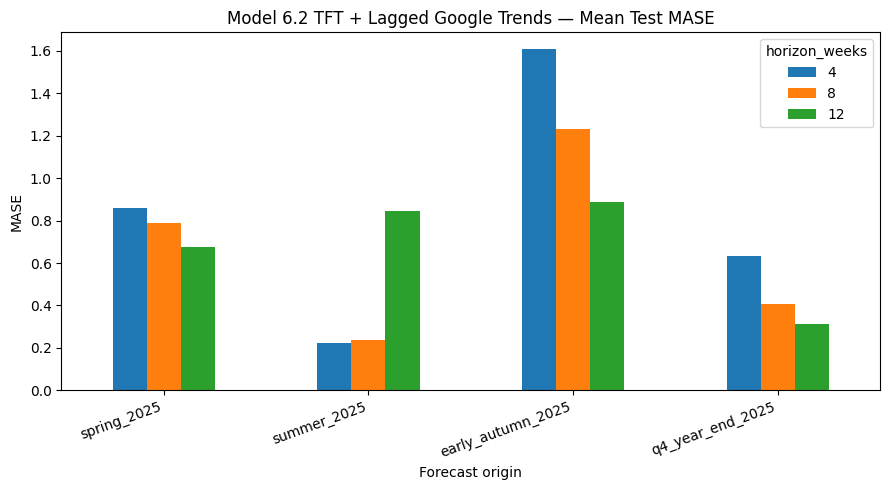

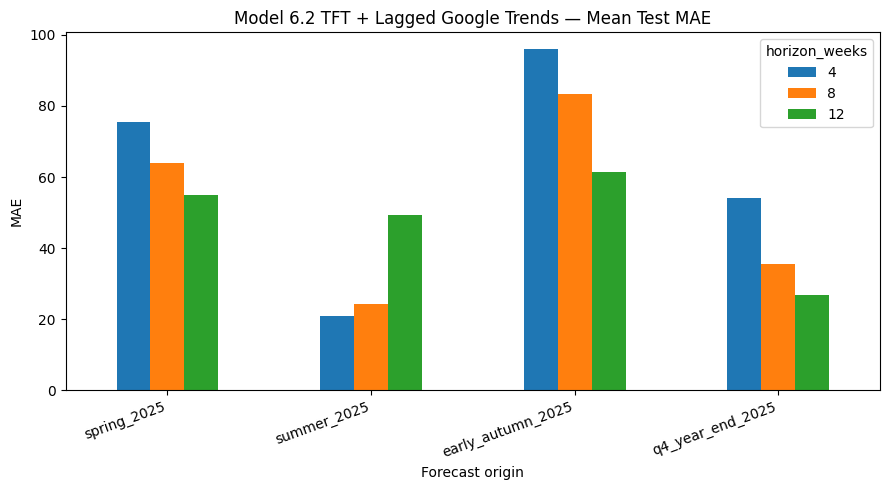

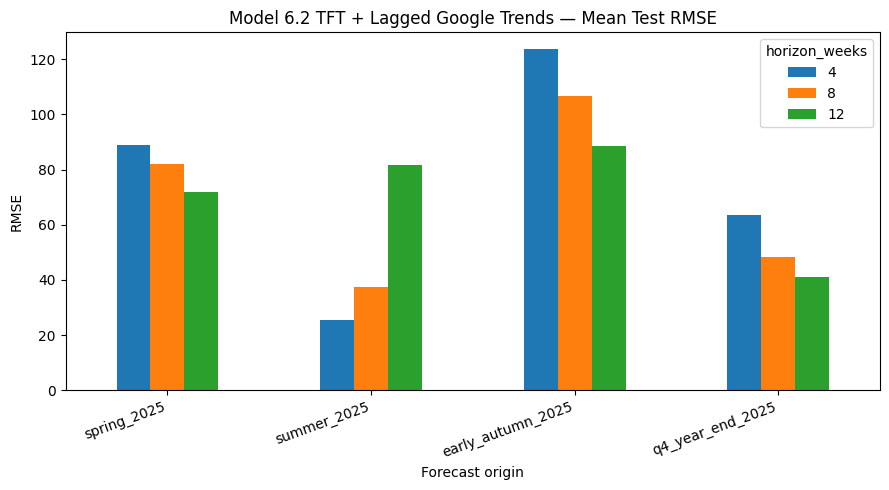

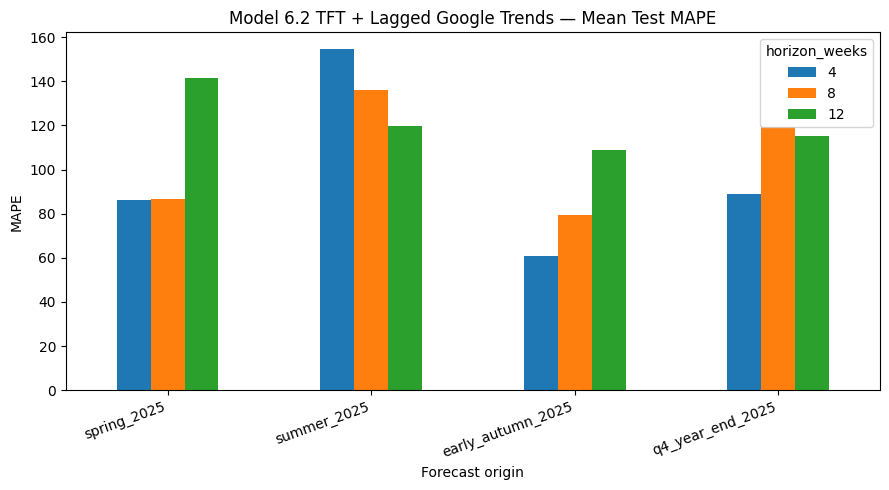

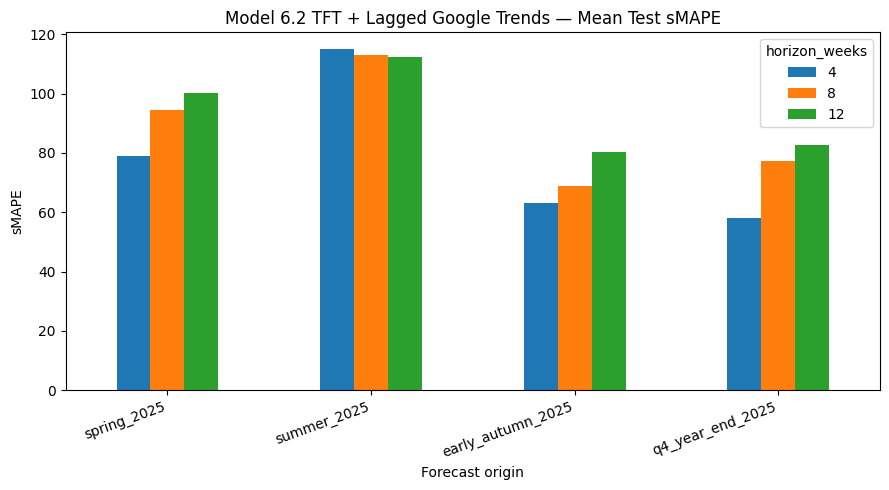

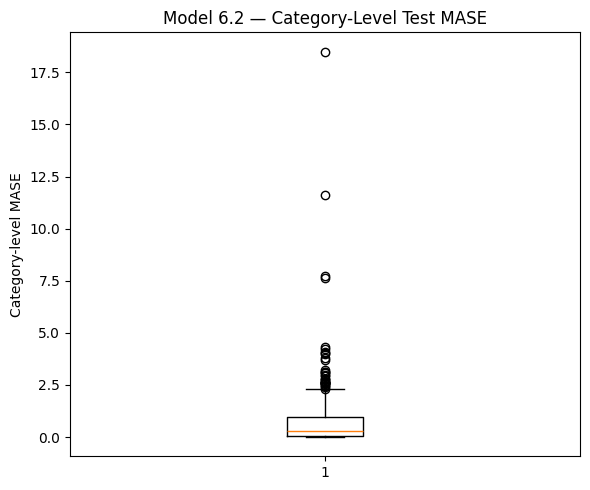

In [55]:
scenario_summary=(test_df.groupby(["scenario_id","outer_origin_label","horizon_weeks"],as_index=False)
    .agg(MAE=("MAE","mean"),RMSE=("RMSE","mean"),MAPE=("MAPE","mean"),sMAPE=("sMAPE","mean"),
         MASE=("MASE","mean"),median_MASE=("MASE","median"),valid_MASE_N=("MASE","count")))
overall_summary=pd.DataFrame([{"mean_MAE":test_df.MAE.mean(),"mean_RMSE":test_df.RMSE.mean(),
    "mean_MAPE":test_df.MAPE.mean(),"mean_sMAPE":test_df.sMAPE.mean(),"mean_MASE":test_df.MASE.mean(),
    "median_MASE":test_df.MASE.median(),"valid_MASE_evaluations":int(test_df.MASE.notna().sum()),
    "undefined_MASE_evaluations":int(test_df.MASE.isna().sum()),"total_evaluations":len(test_df)}])
scenario_summary.to_csv(OUTPUT_DIR/"model_6_2_scenario_summary.csv",index=False)
overall_summary.to_csv(OUTPUT_DIR/"model_6_2_overall_summary.csv",index=False)
print("SCENARIO SUMMARY"); display(scenario_summary)
print("OVERALL SUMMARY"); display(overall_summary)
for metric in ["MASE","MAE","RMSE","MAPE","sMAPE"]:
    piv=scenario_summary.pivot(index="outer_origin_label",columns="horizon_weeks",values=metric).reindex(OUTER_ORIGINS.keys())
    ax=piv.plot(kind="bar",figsize=(9,5)); ax.set_title(f"Model 6.2 TFT + Lagged Google Trends — Mean Test {metric}")
    ax.set_ylabel(metric); ax.set_xlabel("Forecast origin"); plt.xticks(rotation=20,ha="right"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/f"plot_test_{metric.lower()}_by_origin_horizon.png",dpi=160); plt.show()
plt.figure(figsize=(6,5)); plt.boxplot(test_df.MASE.dropna()); plt.ylabel("Category-level MASE")
plt.title("Model 6.2 — Category-Level Test MASE"); plt.tight_layout()
plt.savefig(OUTPUT_DIR/"plot_category_mase_distribution.png",dpi=160); plt.show()

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch

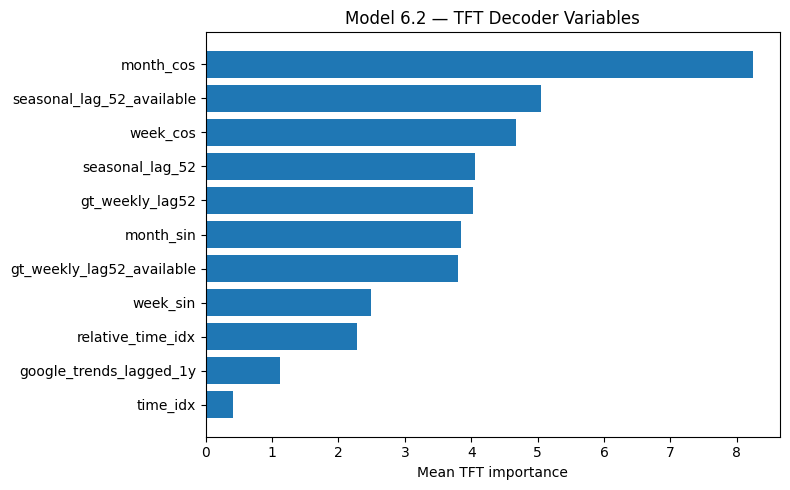

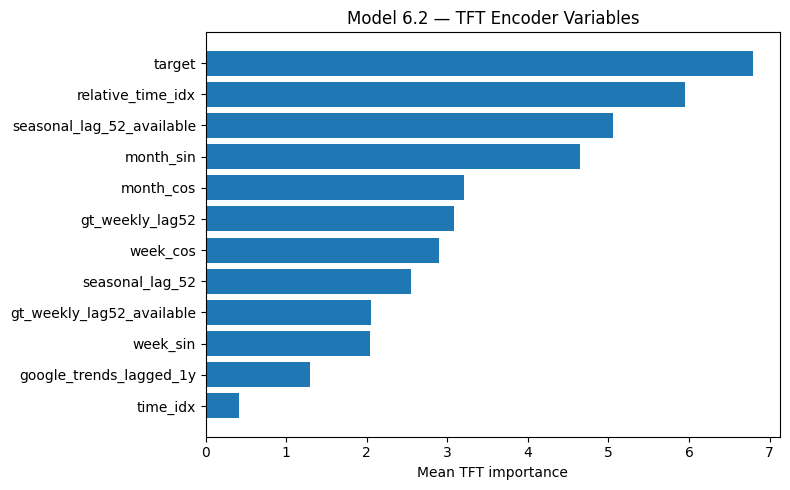

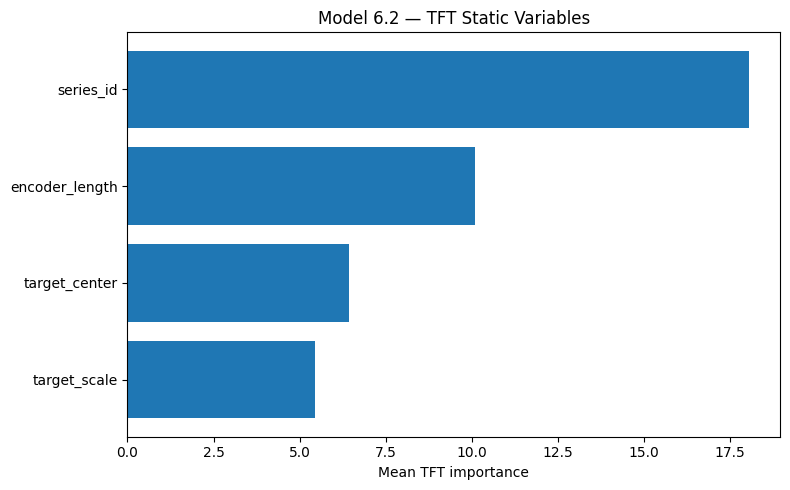

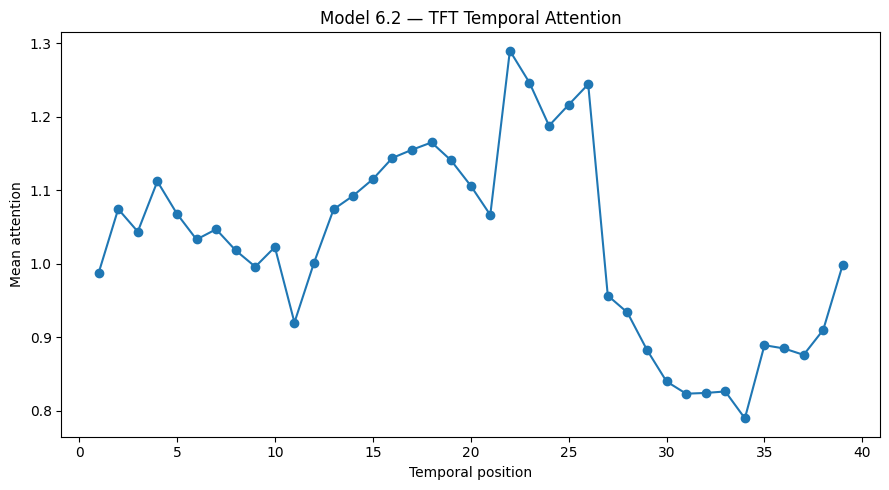

In [56]:
interpretation_rows=[]; attention_rows=[]
for origin_label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s); model=models_by_origin[origin_label]; training=training_by_origin[origin_label]
    pf=prediction_frame(origin,MAX_HORIZON)
    ds=TimeSeriesDataSet.from_dataset(training,pf,predict=True,stop_randomization=True)
    loader=ds.to_dataloader(train=False,batch_size=64,num_workers=0)
    try:
        raw=model.predict(loader,mode="raw",return_x=True); raw_output=raw.output if hasattr(raw,"output") else raw[0]
        interpretation=model.interpret_output(raw_output,reduction="sum")
        for key in ["static_variables","encoder_variables","decoder_variables"]:
            if key in interpretation:
                vals=interpretation[key]; vals=vals.detach().cpu().numpy() if torch.is_tensor(vals) else np.asarray(vals); vals=np.asarray(vals).reshape(-1)
                names={"static_variables":list(model.static_variables),"encoder_variables":list(model.encoder_variables),"decoder_variables":list(model.decoder_variables)}[key]
                for name,val in zip(names,vals): interpretation_rows.append({"outer_origin_label":origin_label,"importance_type":key,"variable":name,"importance":float(val)})
        if "attention" in interpretation:
            att=interpretation["attention"]; att=att.detach().cpu().numpy() if torch.is_tensor(att) else np.asarray(att); att=np.asarray(att).reshape(-1)
            for pos,val in enumerate(att,1): attention_rows.append({"outer_origin_label":origin_label,"relative_position":pos,"attention":float(val)})
    except Exception as e: print(f"Native interpretation warning for {origin_label}: {e}")
native_importance_df=pd.DataFrame(interpretation_rows); attention_df=pd.DataFrame(attention_rows)
if len(native_importance_df):
    native_importance_df.to_csv(OUTPUT_DIR/"model_6_2_tft_native_variable_importance.csv",index=False)
    pi=native_importance_df.groupby(["importance_type","variable"],as_index=False).importance.mean()
    for typ,g in pi.groupby("importance_type"):
        g=g.sort_values("importance").tail(15); plt.figure(figsize=(8,5)); plt.barh(g.variable,g.importance)
        plt.xlabel("Mean TFT importance"); plt.title(f"Model 6.2 — TFT {typ.replace('_',' ').title()}"); plt.tight_layout()
        plt.savefig(OUTPUT_DIR/f"plot_tft_{typ}.png",dpi=160); plt.show()
if len(attention_df):
    attention_df.to_csv(OUTPUT_DIR/"model_6_2_tft_attention.csv",index=False)
    g=attention_df.groupby("relative_position",as_index=False).attention.mean(); plt.figure(figsize=(9,5)); plt.plot(g.relative_position,g.attention,marker="o")
    plt.xlabel("Temporal position"); plt.ylabel("Mean attention"); plt.title("Model 6.2 — TFT Temporal Attention"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"plot_tft_temporal_attention.png",dpi=160); plt.show()

SHAP features for selected TFT: ['forecast_step', 'category_code', 'seasonal_lag_52', 'google_trends_lagged_1y', 'gt_weekly_lag52', 'gt_weekly_lag52_available', 'week_sin', 'week_cos', 'month_sin', 'month_cos']
SHAP surrogate fidelity R^2: 0.9934
SHAP surrogate fidelity MAE: 8.0683


,feature,mean_abs_shap,relative_importance_pct
2,seasonal_lag_52,113.915897,80.394608
1,category_code,10.772411,7.602484
0,forecast_step,2.903176,2.048877
7,week_cos,2.676827,1.889134
9,month_cos,2.635062,1.859659
3,google_trends_lagged_1y,2.455419,1.732879
4,gt_weekly_lag52,2.312857,1.632268
8,month_sin,2.137441,1.508470
6,week_sin,1.886852,1.331621
5,gt_weekly_lag52_available,0.000000,0.000000


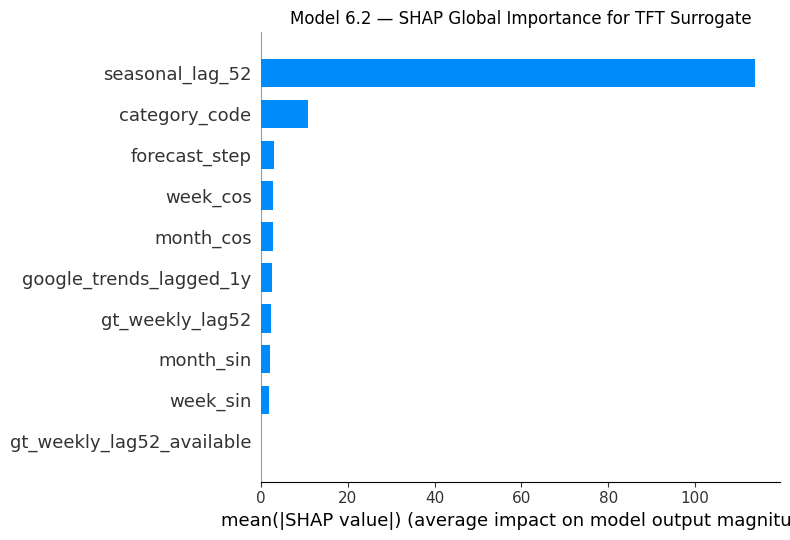

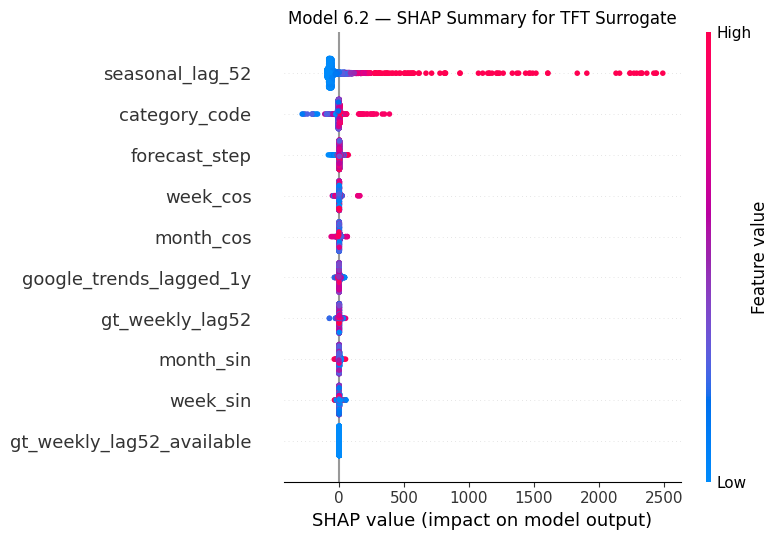

<Figure size 800x600 with 0 Axes>

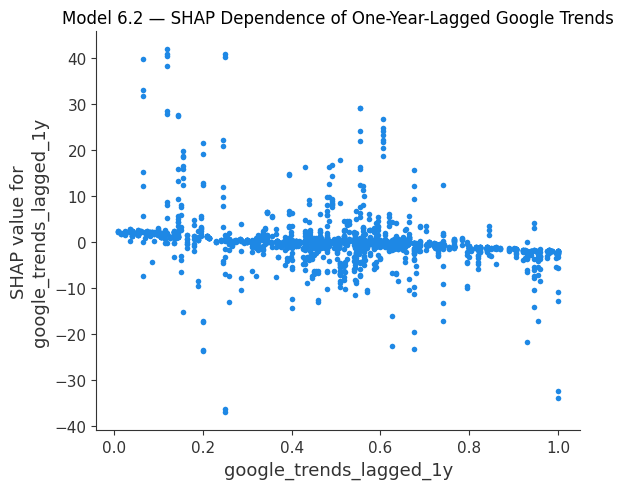

<Figure size 800x600 with 0 Axes>

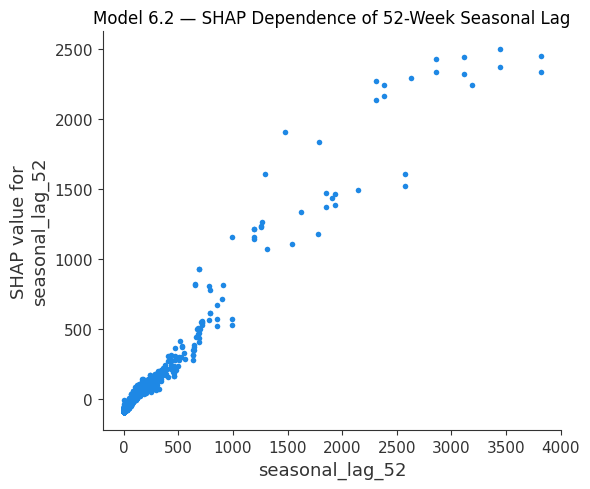

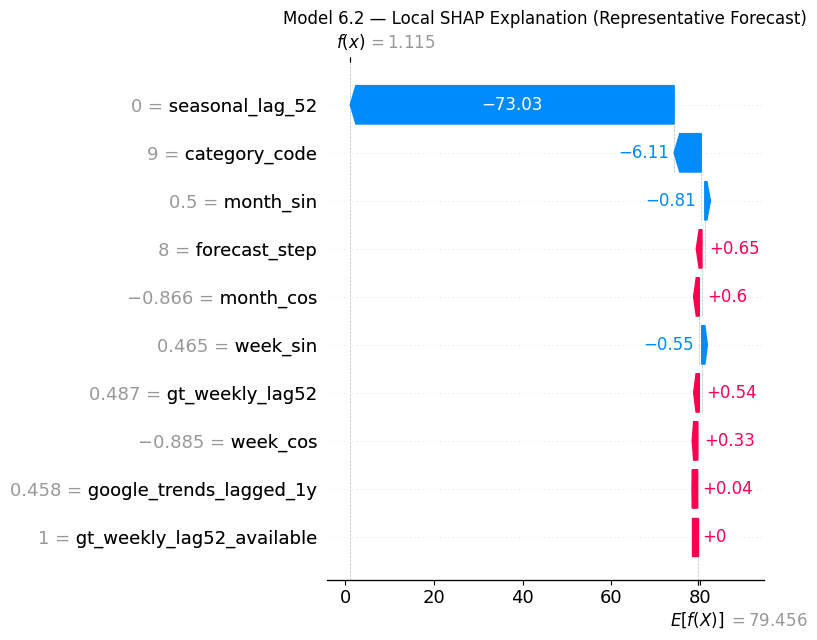

In [57]:
shap_df=forecasts_df.copy(); dt=pd.to_datetime(shap_df.week)
shap_df["week_of_year"]=dt.dt.isocalendar().week.astype(float); shap_df["week_sin"]=np.sin(2*np.pi*shap_df.week_of_year/52.0); shap_df["week_cos"]=np.cos(2*np.pi*shap_df.week_of_year/52.0)
shap_df["month"]=dt.dt.month.astype(float); shap_df["month_sin"]=np.sin(2*np.pi*shap_df.month/12.0); shap_df["month_cos"]=np.cos(2*np.pi*shap_df.month/12.0)
shap_df["category_code"]=pd.Categorical(shap_df.category,categories=categories).codes.astype(float)

selected_trend_features = CANDIDATE_TRENDS[SELECTED_CANDIDATE]
shap_features = (["forecast_step", "category_code", "seasonal_lag_52"]
                 + selected_trend_features
                 + ["week_sin", "week_cos", "month_sin", "month_cos"])
assert set(selected_trend_features).issubset(KNOWN_REALS)
assert "gt_weekly_residual_lag52" not in shap_features or SELECTED_CANDIDATE == "monthly_residual"
print("SHAP features for selected TFT:", shap_features)
X=shap_df[shap_features].astype(float); y_tft=shap_df.y_pred.astype(float)
surrogate=ExtraTreesRegressor(n_estimators=500,min_samples_leaf=2,random_state=SEED,n_jobs=-1).fit(X,y_tft)
surrogate_pred=surrogate.predict(X); surrogate_r2=r2_score(y_tft,surrogate_pred); surrogate_mae=mae(y_tft,surrogate_pred)
print(f"SHAP surrogate fidelity R^2: {surrogate_r2:.4f}"); print(f"SHAP surrogate fidelity MAE: {surrogate_mae:.4f}")
fidelity_df=pd.DataFrame([{"surrogate_r2_to_tft_predictions":surrogate_r2,"surrogate_mae_to_tft_predictions":surrogate_mae,"n_explanation_rows":len(X)}])
fidelity_df.to_csv(OUTPUT_DIR/"model_6_2_shap_surrogate_fidelity.csv",index=False)
explainer=shap.TreeExplainer(surrogate); shap_values=explainer.shap_values(X)
if isinstance(shap_values,list): shap_values=shap_values[0]
shap_values=np.asarray(shap_values)
shap_importance=pd.DataFrame({"feature":shap_features,"mean_abs_shap":np.mean(np.abs(shap_values),axis=0)}).sort_values("mean_abs_shap",ascending=False)
shap_importance["relative_importance_pct"]=100*shap_importance.mean_abs_shap/shap_importance.mean_abs_shap.sum()
shap_importance.to_csv(OUTPUT_DIR/"model_6_2_shap_global_importance.csv",index=False); display(shap_importance)
plt.figure(figsize=(9,6)); shap.summary_plot(shap_values,X,plot_type="bar",show=False); plt.title("Model 6.2 — SHAP Global Importance for TFT Surrogate"); plt.tight_layout(); plt.savefig(OUTPUT_DIR/"plot_shap_global_bar.png",dpi=180,bbox_inches="tight"); plt.show()
plt.figure(figsize=(9,6)); shap.summary_plot(shap_values,X,show=False); plt.title("Model 6.2 — SHAP Summary for TFT Surrogate"); plt.tight_layout(); plt.savefig(OUTPUT_DIR/"plot_shap_beeswarm.png",dpi=180,bbox_inches="tight"); plt.show()
for feature,title,file in [("google_trends_lagged_1y","SHAP Dependence of One-Year-Lagged Google Trends","plot_shap_dependence_google_trends.png"),("seasonal_lag_52","SHAP Dependence of 52-Week Seasonal Lag","plot_shap_dependence_seasonal_lag52.png")]:
    plt.figure(figsize=(8,6)); shap.dependence_plot(feature,shap_values,X,interaction_index=None,show=False); plt.title(f"Model 6.2 — {title}"); plt.tight_layout(); plt.savefig(OUTPUT_DIR/file,dpi=180,bbox_inches="tight"); plt.show()

idx=int(np.argmin(np.abs(shap_df.y_pred.to_numpy(float)-shap_df.y_pred.median())))
base=np.asarray(explainer.expected_value).reshape(-1)[0]
local=shap.Explanation(values=shap_values[idx],base_values=float(base),data=X.iloc[idx].to_numpy(float),feature_names=list(X.columns))
shap.plots.waterfall(local,max_display=min(12,X.shape[1]),show=False); plt.title("Model 6.2 — Local SHAP Explanation (Representative Forecast)"); plt.tight_layout(); plt.savefig(OUTPUT_DIR/"plot_shap_waterfall_representative.png",dpi=180,bbox_inches="tight"); plt.show()

In [58]:
audit=[]
audit.append(("outer_origins_match_common_framework",OUTER_ORIGINS=={"spring_2025":"2025-04-07","summer_2025":"2025-07-07","early_autumn_2025":"2025-09-08","q4_year_end_2025":"2025-10-06"}))
audit.append(("forecast_horizons_are_4_8_12",FORECAST_HORIZONS==[4,8,12]))
audit.append(("only_trends_feature_selection_on_pre2025_inner_validation",bool(max(map(pd.Timestamp,INNER_ORIGINS))<pd.Timestamp("2025-01-01"))))
audit.append(("same_encoder_feature_set_architecture_epochs_as_6_1",best_params=={k:LOCKED_6_1[k] for k in best_params} and BEST_EPOCHS==LOCKED_6_1["final_epochs"]))
audit.append(("only_incremental_known_real_is_google_trends",[x for x in KNOWN_REALS if x not in BASE_KNOWN_REALS]==CANDIDATE_TRENDS[SELECTED_CANDIDATE]))
audit.append(("all_trend_values_finite",bool(np.isfinite(weekly.google_trends_lagged_1y).all())))
audit.append(("trend_alignment_is_exactly_one_calendar_year",bool((weekly.trend_source_year==weekly.week.dt.year-1).all() and (weekly.trend_source_month==weekly.week.dt.month).all())))
for label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s); dec=weekly[(weekly.week>=origin)&(weekly.week<origin+pd.Timedelta(weeks=MAX_HORIZON))]
    audit.append((f"{label}_trend_sources_pre_origin",bool((dec.trend_source_date<origin).all())))
    lag_source=dec.week-pd.Timedelta(weeks=52); audit.append((f"{label}_lag52_sources_pre_origin",bool((lag_source<origin).all())))
audit.append(("outer_training_strictly_pre_origin",bool((pd.to_datetime(meta_df.training_end)<pd.to_datetime(meta_df.outer_origin)).all())))
audit.append(("expected_480_category_horizon_evaluations",len(test_df)==480))
audit.append(("expected_1920_weekly_outer_forecasts",len(forecasts_df)==1920))
audit.append(("all_predictions_nonnegative",bool((forecasts_df.y_pred>=0).all())))
audit.append(("mase_period_is_52",SEASONAL_PERIOD==52))
audit_df=pd.DataFrame(audit,columns=["check","passed"]); display(audit_df)
if not audit_df.passed.all(): raise AssertionError("One or more integrity checks failed")
audit_df.to_csv(OUTPUT_DIR/"model_6_2_integrity_audit.csv",index=False)
print("All integrity checks passed.")

,check,passed
0,outer_origins_match_common_framework,True
1,forecast_horizons_are_4_8_12,True
2,only_trends_feature_selection_on_pre2025_inner...,True
3,same_encoder_feature_set_architecture_epochs_a...,True
4,only_incremental_known_real_is_google_trends,True
5,all_trend_values_finite,True
6,trend_alignment_is_exactly_one_calendar_year,True
7,spring_2025_trend_sources_pre_origin,True
8,spring_2025_lag52_sources_pre_origin,True
9,summer_2025_trend_sources_pre_origin,True


All integrity checks passed.


In [59]:
previous=pd.DataFrame({
"Model":["Model 1 Statistical","Model 2 Global Trees","Model 3 Stacked LSTM","Model 4 Cluster Hybrid","Model 5 Expert Ensemble","Model 6.1 TFT Only"],
"MASE":[1.031349,1.267,4.265,1.71034,0.864366,0.828728],
"Median_MASE":[0.468898,0.532,0.290,0.564621,0.398887,0.302778],
"MAE":[72.885009,63.76,221.35,70.656172,59.333863,55.818099],
"RMSE":[88.827605,86.55,274.83,90.433673,76.283266,73.474507],
"MAPE":[215.011254,101.95,554.94,187.388726,164.831888,117.101196],
"sMAPE":[81.804379,130.54,120.46,107.389743,115.230166,91.356196]})
row=pd.DataFrame({"Model":["Model 6.2 TFT + Lagged Google Trends"],"MASE":[overall_summary.loc[0,"mean_MASE"]],"Median_MASE":[overall_summary.loc[0,"median_MASE"]],"MAE":[overall_summary.loc[0,"mean_MAE"]],"RMSE":[overall_summary.loc[0,"mean_RMSE"]],"MAPE":[overall_summary.loc[0,"mean_MAPE"]],"sMAPE":[overall_summary.loc[0,"mean_sMAPE"]]})
comparison=pd.concat([previous,row],ignore_index=True); comparison.to_csv(OUTPUT_DIR/"model_6_2_all_model_descriptive_comparison.csv",index=False); display(comparison)
ablation=comparison[comparison.Model.isin(["Model 6.1 TFT Only","Model 6.2 TFT + Lagged Google Trends"])].copy()
ablation.to_csv(OUTPUT_DIR/"model_6_tft_google_trends_ablation_summary.csv",index=False); print("6.1 vs 6.2 ABLATION"); display(ablation)

,Model,MASE,Median_MASE,MAE,RMSE,MAPE,sMAPE
0,Model 1 Statistical,1.031349,0.468898,72.885009,88.827605,215.011254,81.804379
1,Model 2 Global Trees,1.267000,0.532000,63.760000,86.550000,101.950000,130.540000
2,Model 3 Stacked LSTM,4.265000,0.290000,221.350000,274.830000,554.940000,120.460000
3,Model 4 Cluster Hybrid,1.710340,0.564621,70.656172,90.433673,187.388726,107.389743
4,Model 5 Expert Ensemble,0.864366,0.398887,59.333863,76.283266,164.831888,115.230166
5,Model 6.1 TFT Only,0.828728,0.302778,55.818099,73.474507,117.101196,91.356196
6,Model 6.2 TFT + Lagged Google Trends,0.725564,0.266689,53.837626,71.595661,110.644519,87.044163


6.1 vs 6.2 ABLATION


,Model,MASE,Median_MASE,MAE,RMSE,MAPE,sMAPE
5,Model 6.1 TFT Only,0.828728,0.302778,55.818099,73.474507,117.101196,91.356196
6,Model 6.2 TFT + Lagged Google Trends,0.725564,0.266689,53.837626,71.595661,110.644519,87.044163


In [60]:
excel_path=OUTPUT_DIR/"model_6_2_tft_trends_all_results.xlsx"
with pd.ExcelWriter(excel_path,engine="openpyxl") as writer:
    pd.DataFrame([LOCKED_6_1]).to_excel(writer,sheet_name="Locked_6_1_Config",index=False)
    scenarios.to_excel(writer,sheet_name="Scenarios",index=False)
    test_df.to_excel(writer,sheet_name="Outer_Test_Metrics",index=False)
    forecasts_df.to_excel(writer,sheet_name="Outer_Forecasts",index=False)
    scenario_summary.to_excel(writer,sheet_name="Scenario_Summary",index=False)
    overall_summary.to_excel(writer,sheet_name="Overall_Summary",index=False)
    meta_df.to_excel(writer,sheet_name="Outer_Model_Metadata",index=False)
    audit_df.to_excel(writer,sheet_name="Integrity_Audit",index=False)
    comparison.to_excel(writer,sheet_name="All_Model_Comparison",index=False)
    ablation.to_excel(writer,sheet_name="TFT_Ablation",index=False)
    fidelity_df.to_excel(writer,sheet_name="SHAP_Fidelity",index=False)
    shap_importance.to_excel(writer,sheet_name="SHAP_Importance",index=False)
    if len(native_importance_df): native_importance_df.to_excel(writer,sheet_name="TFT_Variable_Importance",index=False)
    if len(attention_df): attention_df.to_excel(writer,sheet_name="TFT_Attention",index=False)
print("Saved:",excel_path)
print("Detailed forecasts for final significance testing:",OUTPUT_DIR/"model_6_2_outer_forecasts.csv")

Saved: /content/drive/MyDrive/model_6_2_trends_inner_validated_shap/model_6_2_tft_trends_all_results.xlsx
Detailed forecasts for final significance testing: /content/drive/MyDrive/model_6_2_trends_inner_validated_shap/model_6_2_outer_forecasts.csv


In [61]:
from scipy.stats import wilcoxon
baseline_dir=BASE_DIR/'model_6_1_tft_only_outputs'
baseline_results=pd.read_csv(baseline_dir/'model_6_1_outer_test_results.csv')
baseline_forecasts=pd.read_csv(baseline_dir/'model_6_1_outer_forecasts.csv')

key=['outer_origin_label','category','forecast_step']
a=forecasts_df[key+['y_true']].copy();b=baseline_forecasts[key+['y_true']].copy()
assert not a.duplicated(key).any() and not b.duplicated(key).any()
check=a.merge(b,on=key,how='outer',validate='one_to_one',indicator=True,suffixes=('_new','_baseline'))
assert len(check)==1920 and check._merge.eq('both').all()
assert np.allclose(check.y_true_new,check.y_true_baseline,rtol=0,atol=1e-9)
print('PASS: exact 1,920 paired forecast targets')

keys=['outer_origin_label','horizon_weeks','category']
comp=test_df[keys+['MASE']].merge(baseline_results[keys+['MASE']],on=keys,validate='one_to_one',suffixes=('_M62','_M61'),indicator=True)
assert len(comp)==480 and comp._merge.eq('both').all()
assert comp.MASE_M62.notna().equals(comp.MASE_M61.notna())
cat=comp.groupby('category',as_index=False)[['MASE_M61','MASE_M62']].mean().dropna()
assert len(cat)==39
cat['delta_M61_minus_M62']=cat.MASE_M61-cat.MASE_M62
cat.to_csv(OUTPUT_DIR/'paired_category_diagnostics.csv',index=False,encoding='utf-8-sig')
d=cat.delta_M61_minus_M62.to_numpy(float)
pval=float(wilcoxon(d,alternative='two-sided',zero_method='wilcox').pvalue)
rng=np.random.default_rng(42)
boot=np.mean(rng.choice(d,size=(20000,len(d)),replace=True),axis=1)
ci=np.quantile(boot,[.025,.975])
summary=pd.DataFrame([{'n_categories':len(cat),'MASE_M61':float(comp.MASE_M61.mean()),'MASE_M62':float(comp.MASE_M62.mean()),'mean_delta_M61_minus_M62':float(np.mean(d)),'median_delta':float(np.median(d)),'categories_improved':int((d>0).sum()),'categories_worsened':int((d<0).sum()),'wilcoxon_two_sided_p':pval,'bootstrap_mean_delta_ci95_low':float(ci[0]),'bootstrap_mean_delta_ci95_high':float(ci[1]),'exploratory_test_reused':True}])
summary.to_csv(OUTPUT_DIR/'paired_statistical_summary.csv',index=False)
display(summary.T)
print('Two-sided Wilcoxon p<0.05:',pval<.05)
print('CAUTION: Outer 2025 origins already inspected: exploratory inference only.')


PASS: exact 1,920 paired forecast targets


,0
n_categories,39
MASE_M61,0.828728
MASE_M62,0.725564
mean_delta_M61_minus_M62,0.103164
median_delta,0.007956
categories_improved,25
categories_worsened,14
wilcoxon_two_sided_p,0.014285
bootstrap_mean_delta_ci95_low,0.035574
bootstrap_mean_delta_ci95_high,0.182573


Two-sided Wilcoxon p<0.05: True
CAUTION: Outer 2025 origins already inspected: exploratory inference only.


,0
n_category_blocks,39
mase_baseline_row_mean,0.828728
mase_m62_row_mean,0.725564
relative_mase_reduction_pct,12.448482
mean_category_delta_m61_minus_m62,0.103164
median_category_delta_m61_minus_m62,0.007956
category_wins_m62,25
category_losses_m62,14
wilcoxon_two_sided_p,0.014285
paired_rank_biserial,0.462304


Descriptive results by origin:


,outer_origin_label,n_category_horizon_pairs,mase_m61,mase_m62,mean_delta,median_delta
0,early_autumn_2025,117,1.468414,1.242113,0.226301,1.813369e-12
1,q4_year_end_2025,117,0.637563,0.450520,0.187043,6.367315e-11
2,spring_2025,117,0.772691,0.774363,-0.001673,-1.046099e-13
3,summer_2025,117,0.436245,0.435261,0.000984,-9.159340e-16


Descriptive results by horizon:


,horizon_weeks,n_category_origin_pairs,mase_m61,mase_m62,mean_delta,median_delta
0,4,156,0.991390,0.830052,0.161338,1.854504e-22
1,8,156,0.749545,0.665635,0.083910,0.000000e+00
2,12,156,0.745249,0.681004,0.064244,3.747003e-16


Descriptive results by origin × horizon:


,outer_origin_label,horizon_weeks,n_categories,mase_m61,mase_m62,mean_delta
0,early_autumn_2025,4,39,1.968725,1.607124,0.361601
1,early_autumn_2025,8,39,1.411857,1.231299,0.180558
2,early_autumn_2025,12,39,1.024660,0.887915,0.136744
3,q4_year_end_2025,4,39,0.919581,0.633159,0.286421
4,q4_year_end_2025,8,39,0.568745,0.404411,0.164334
5,q4_year_end_2025,12,39,0.424363,0.313989,0.110374
6,spring_2025,4,39,0.870668,0.857671,0.012996
7,spring_2025,8,39,0.792954,0.789987,0.002967
8,spring_2025,12,39,0.654450,0.675431,-0.020981
9,summer_2025,4,39,0.206587,0.222255,-0.015668


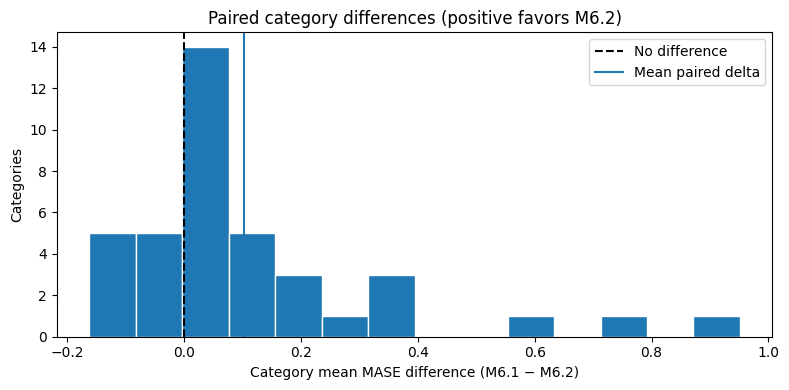

INTERPRETATION: exploratory, not an independent confirmatory p-value.


In [62]:
from scipy.stats import wilcoxon

PUB_RNG_SEED = 20261019
N_PERMUTATIONS = 100_000
N_BOOTSTRAPS = 20_000
rng_pub = np.random.default_rng(PUB_RNG_SEED)

assert len(comp) == 480 and len(cat) == 39
assert not comp.duplicated(['outer_origin_label','horizon_weeks','category']).any()
assert set(comp.loc[comp.MASE_M61.notna(),'category']) == set(cat.category)
delta = cat['delta_M61_minus_M62'].to_numpy(dtype=float)
assert np.isfinite(delta).all() and len(delta) == 39

wilcoxon_result = wilcoxon(delta, alternative='two-sided', zero_method='wilcox')

observed_mean = float(delta.mean())
permutation_extreme = 0
chunk = 2000
for start in range(0, N_PERMUTATIONS, chunk):
    k = min(chunk, N_PERMUTATIONS-start)
    signs = rng_pub.choice(np.array([-1., 1.]), size=(k, len(delta)))
    means = (signs * delta).mean(axis=1)
    permutation_extreme += int(np.count_nonzero(np.abs(means) >= abs(observed_mean)-1e-14))
permutation_p = (permutation_extreme+1)/(N_PERMUTATIONS+1)

from scipy.stats import rankdata
nonzero = delta[np.abs(delta) > 1e-12]
ranks = rankdata(np.abs(nonzero), method='average')
w_plus = float(ranks[nonzero > 0].sum())
w_minus = float(ranks[nonzero < 0].sum())
rank_biserial = (w_plus-w_minus)/(w_plus+w_minus)

bootstrap_means = np.empty(N_BOOTSTRAPS)
bootstrap_medians = np.empty(N_BOOTSTRAPS)
for start in range(0, N_BOOTSTRAPS, chunk):
    k = min(chunk, N_BOOTSTRAPS-start)
    samples = rng_pub.choice(delta, size=(k,len(delta)), replace=True)
    bootstrap_means[start:start+k] = samples.mean(axis=1)
    bootstrap_medians[start:start+k] = np.median(samples,axis=1)
mean_ci = np.quantile(bootstrap_means,[0.025,0.975])
median_ci = np.quantile(bootstrap_medians,[0.025,0.975])

pub_stats = pd.DataFrame([{
    'n_category_blocks':len(delta),
    'mase_baseline_row_mean':float(comp.MASE_M61.mean()),
    'mase_m62_row_mean':float(comp.MASE_M62.mean()),
    'relative_mase_reduction_pct':100*(1-float(comp.MASE_M62.mean())/float(comp.MASE_M61.mean())),
    'mean_category_delta_m61_minus_m62':observed_mean,
    'median_category_delta_m61_minus_m62':float(np.median(delta)),
    'category_wins_m62':int((delta>0).sum()),
    'category_losses_m62':int((delta<0).sum()),
    'wilcoxon_two_sided_p':float(wilcoxon_result.pvalue),
    'paired_rank_biserial':float(rank_biserial),
    'sign_flip_mean_two_sided_mc_p':float(permutation_p),
    'permutation_draws':N_PERMUTATIONS,
    'bootstrap_draws':N_BOOTSTRAPS,
    'mean_delta_bootstrap_ci95_low':float(mean_ci[0]),
    'mean_delta_bootstrap_ci95_high':float(mean_ci[1]),
    'median_delta_bootstrap_ci95_low':float(median_ci[0]),
    'median_delta_bootstrap_ci95_high':float(median_ci[1]),
    'primary_unit':'category',
    'test_period_reused_exploratory':True,
}])
pub_stats.to_csv(OUTPUT_DIR/'paired_inference.csv',index=False)
display(pub_stats.T)

paired_valid = comp.dropna(subset=['MASE_M61','MASE_M62']).copy()
paired_valid['delta_m61_minus_m62'] = paired_valid.MASE_M61-paired_valid.MASE_M62
by_origin = paired_valid.groupby('outer_origin_label',as_index=False).agg(
    n_category_horizon_pairs=('delta_m61_minus_m62','size'),
    mase_m61=('MASE_M61','mean'),mase_m62=('MASE_M62','mean'),
    mean_delta=('delta_m61_minus_m62','mean'),median_delta=('delta_m61_minus_m62','median'))
by_horizon = paired_valid.groupby('horizon_weeks',as_index=False).agg(
    n_category_origin_pairs=('delta_m61_minus_m62','size'),
    mase_m61=('MASE_M61','mean'),mase_m62=('MASE_M62','mean'),
    mean_delta=('delta_m61_minus_m62','mean'),median_delta=('delta_m61_minus_m62','median'))
by_origin_horizon = paired_valid.groupby(['outer_origin_label','horizon_weeks'],as_index=False).agg(
    n_categories=('delta_m61_minus_m62','size'),
    mase_m61=('MASE_M61','mean'),mase_m62=('MASE_M62','mean'),
    mean_delta=('delta_m61_minus_m62','mean'))
for name,frame in [('by_origin.csv',by_origin),
                   ('by_horizon.csv',by_horizon),
                   ('by_origin_horizon.csv',by_origin_horizon)]:
    frame.to_csv(OUTPUT_DIR/name,index=False)
print('Descriptive results by origin:');display(by_origin)
print('Descriptive results by horizon:');display(by_horizon)
print('Descriptive results by origin × horizon:');display(by_origin_horizon)

fig,ax=plt.subplots(figsize=(8,4))
ax.hist(delta,bins=14,edgecolor='white')
ax.axvline(0,color='black',linestyle='--',label='No difference')
ax.axvline(observed_mean,color='tab:blue',label='Mean paired delta')
ax.set(xlabel='Category mean MASE difference (M6.1 − M6.2)',ylabel='Categories',
       title='Paired category differences (positive favors M6.2)')
ax.legend();fig.tight_layout()
fig.savefig(OUTPUT_DIR/'paired_category_delta_distribution.png',dpi=180)
plt.show()
print('INTERPRETATION: exploratory, not an independent confirmatory p-value.')

In [63]:
inner_report = inner_summary.copy()
assert set(inner_report.candidate) == set(CANDIDATE_TRENDS)
inner_report['evaluation_period']='2024 pre-test inner validation'
inner_report['model']='TFT + '+inner_report.candidate
inner_report['selected_for_2025_outer'] = inner_report.candidate.eq(SELECTED_CANDIDATE)
inner_report.to_csv(OUTPUT_DIR/'inner_validation_ablation.csv',index=False)
outer_ablation = pd.DataFrame([
    {'model':'M6.1 TFT — no Google Trends','evaluation_period':'2025 outer test',
     'mean_MASE':float(comp.MASE_M61.mean()),'n_evaluations':len(comp)},
    {'model':'M6.2 TFT — selected: '+SELECTED_CANDIDATE,'evaluation_period':'2025 outer test',
     'mean_MASE':float(comp.MASE_M62.mean()),'n_evaluations':len(comp)}])
outer_ablation.to_csv(OUTPUT_DIR/'outer_test_ablation.csv',index=False)
print('2024 INNER VALIDATION: candidate selection (not outer ablation)')
display(inner_report)
print('2025 OUTER TEST: true matched ablation, two arms only')
display(outer_ablation)
print('A three-arm outer ablation requires a separately pre-specified monthly-only 2025 evaluation. '
      'Do not label the inner-validation MASE as an outer-test result.')

with pd.ExcelWriter(OUTPUT_DIR/'statistics_and_ablation.xlsx',engine='openpyxl') as writer:
    pub_stats.to_excel(writer,sheet_name='Paired_Inference',index=False)
    cat.to_excel(writer,sheet_name='Category_Differences',index=False)
    by_origin.to_excel(writer,sheet_name='By_Origin',index=False)
    by_horizon.to_excel(writer,sheet_name='By_Horizon',index=False)
    by_origin_horizon.to_excel(writer,sheet_name='Origin_x_Horizon',index=False)
    inner_report.to_excel(writer,sheet_name='Inner_Validation_Ablation',index=False)
    outer_ablation.to_excel(writer,sheet_name='Outer_Test_Ablation',index=False)
print('Saved statistics and ablation reports.')

2024 INNER VALIDATION: candidate selection (not outer ablation)


,candidate,MASE,evaluation_period,model,selected_for_2025_outer
2,monthly_weekly,4.181221,2024 pre-test inner validation,TFT + monthly_weekly,True
1,monthly_residual,5.521593,2024 pre-test inner validation,TFT + monthly_residual,False
0,monthly_only,7.450840,2024 pre-test inner validation,TFT + monthly_only,False


2025 OUTER TEST: true matched ablation, two arms only


,model,evaluation_period,mean_MASE,n_evaluations
0,M6.1 TFT — no Google Trends,2025 outer test,0.828728,480
1,M6.2 TFT — selected: monthly_weekly,2025 outer test,0.725564,480


A three-arm outer ablation requires a separately pre-specified monthly-only 2025 evaluation. Do not label the inner-validation MASE as an outer-test result.
Saved statistics and ablation reports.
